# Stage 1c: Preprocess COVID-19 (Constraint@AAAI 2021)

**Stage:** 1 (preprocessing) · **Runs on:** Kaggle and locally

| | |
|---|---|
| Input | `Constraint_Train.csv`, `Constraint_Val.csv`, `english_test_with_labels.csv` |
| Output | `covid_cleaned.csv` (the only file saved; tables and plots are shown in this notebook) |
| Used for | Task A classification, Task C clustering |

Only the **labelled** files are used. `Constraint_Test.csv` / `Constraint_English_Test.csv` contain
the same test posts **without labels**, so loading them would duplicate posts and add unlabelled rows.

In [1]:
# Setup: import the shared code. Works on Kaggle and locally.
import sys
from pathlib import Path

# Locally, misinfo_utils.py is in <project>/src/. On Kaggle it is an attached Utility Script,
# so this loop finds nothing and the import below still works.
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "src" / "misinfo_utils.py").exists():
        sys.path.insert(0, str(folder / "src"))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import misinfo_utils as mu

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 100)
paths = mu.setup("01c")

misinfo_utils | stage 01c | running on local
  read from : D:\misinfo-project\data\raw, D:\misinfo-project\outputs
  write to  : D:\misinfo-project\outputs\01_preprocess


In [2]:
MIN_WORDS = 5
COVID_FILES = ["Constraint_Train.csv", "Constraint_Val.csv", "english_test_with_labels.csv"]

## 1. Load

In [3]:
parts = []
for name in COVID_FILES:
    part = pd.read_csv(mu.find_file(name))
    if "label" not in part.columns:          # safety net: never load an unlabelled file
        print(f"Skipping {name}: no label column")
        continue
    print(f"{name:30s} {len(part):>6,} rows | columns: {list(part.columns)}")
    parts.append(part)

raw = pd.concat(parts, ignore_index=True)   # ids restart in each file, so they are not used
print("Total:", f"{len(raw):,}", "rows (expected 10,700)")

Constraint_Train.csv            6,420 rows | columns: ['id', 'tweet', 'label']
Constraint_Val.csv              2,140 rows | columns: ['id', 'tweet', 'label']
english_test_with_labels.csv    2,140 rows | columns: ['id', 'tweet', 'label']
Total: 10,700 rows (expected 10,700)


## 2. Labels

In [4]:
raw_label = raw["label"].astype(str).str.strip().str.lower()
print(raw_label.value_counts(dropna=False))

covid = pd.DataFrame({
    "row_id": mu.make_row_ids(len(raw), "covid"),
    "text": raw["tweet"],
    "label": raw_label.map({"real": 0, "fake": 1}),   # anything else -> empty, removed in cleaning
})
print("Unmatched labels:", covid["label"].isna().sum())

label
real    5600
fake    5100
Name: count, dtype: int64
Unmatched labels: 0


## 3. Shortcut checks (BEFORE cleaning)

Real posts mostly come from official accounts (health ministries, CDC), which share a style:
links, hashtags, @mentions. Cleaning removes links, hashtags and mentions, so they are measured
here first. A big difference between the classes means the raw data has a shortcut, which is why
they are removed.

In [5]:
txt = covid["text"].astype(str)
features = {
    "has link": mu.has_url(txt),
    "has #hashtag": txt.str.contains(r"#\w+", regex=True),
    "has @mention": txt.str.contains(r"@\w+", regex=True),
    "mentions CDC": txt.str.contains("CDC", regex=False),
    "mentions WHO": txt.str.contains("WHO", regex=False),
}
shortcut_before = pd.DataFrame({name: (flag.groupby(covid["label"]).mean() * 100).round(1)
                                for name, flag in features.items()}).T
shortcut_before.columns = [mu.LABEL_NAMES[int(c)] for c in shortcut_before.columns]
shortcut_before   # % of posts in each class

,reliable,misleading
has link,69.4,32.2
has #hashtag,50.8,18.2
has @mention,28.2,7.9
mentions CDC,7.0,1.4
mentions WHO,2.2,2.2


## 4. Clean and remove duplicates

In [6]:
covid_clean, log = mu.clean_and_deduplicate(covid, MIN_WORDS, target_col="label")
covid_clean = mu.to_clean_schema(covid_clean, "covid")
pd.Series(log, name="rows").to_frame()

,rows
loaded,10700
after_missing_target,10700
after_empty_text,10698
after_min_length,10646
after_conflict_removal,10646
after_dedup,10280


In [7]:
txt = covid_clean["text"]
shortcut_after = pd.DataFrame({
    "has link": mu.has_url(txt), "has #hashtag": txt.str.contains(r"#\w+", regex=True),
    "has @mention": txt.str.contains(r"@\w+", regex=True),
}).groupby(covid_clean["label"]).mean().mul(100).round(1).T
shortcut_after.columns = [mu.LABEL_NAMES[int(c)] for c in shortcut_after.columns]
shortcut_after   # should be ~0 everywhere after cleaning

,reliable,misleading
has link,0.0,0.0
has #hashtag,0.0,0.0
has @mention,0.0,0.0


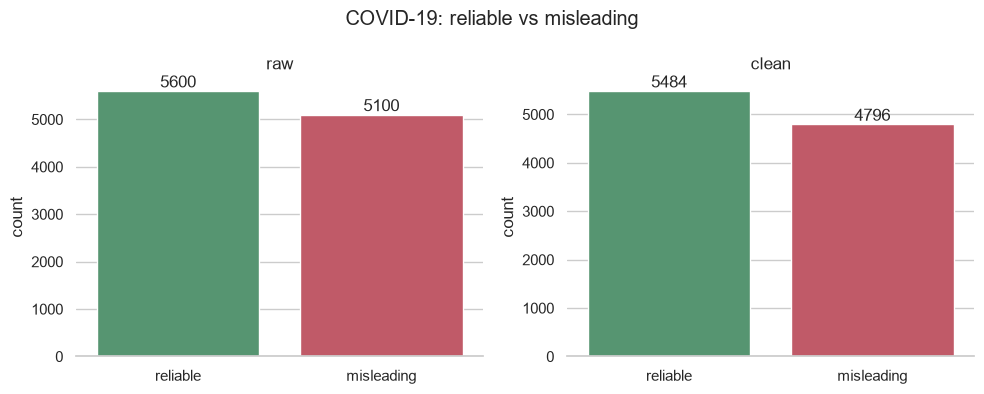

In [8]:
mu.plot_label_counts({"raw": covid, "clean": covid_clean}, "COVID-19: reliable vs misleading")

## 5. Save

In [9]:
mu.save_clean_dataset(covid_clean, "covid")
covid_clean.head()

Saved 10,280 rows -> D:\misinfo-project\outputs\01_preprocess\covid_cleaned.csv


,row_id,text,label,score,source_dataset,sub_source,n_words,had_url
0,covid_000000,The CDC currently reports 99031 deaths. In general the discrepancies in death counts between dif...,0,<NA>,covid,covid,29,False
1,covid_000001,States reported 1121 deaths a small rise from last Tuesday. Southern states reported 640 of thos...,0,<NA>,covid,covid,17,True
2,covid_000002,Politically Correct Woman (Almost) Uses Pandemic as Excuse Not to Reuse Plastic Bag,1,<NA>,covid,covid,13,True
3,covid_000003,: We have 1524 testing laboratories in India and as on 25th August 2020 36827520 tests have been...,0,<NA>,covid,covid,21,True
4,covid_000004,Populous states can generate large case counts but if you look at the new cases per million toda...,0,<NA>,covid,covid,41,True


**Next stage:** `02_merge_and_split` reads this file. On Kaggle, save this notebook with
**Save Version → Save & Run All**, then add it as an input to `02_merge_and_split`.